# SECOM 모델링

## 1. 데이터 로딩
README 6번 코드 그대로 `X`(590), `y`(라벨+타임스탬프), `df`, `yb`(1 = Fail), `X2`(대표 변수 282개)를 만든다.

In [7]:
import time; _t0 = time.time(); print(f"[셀 시작] {time.strftime('%H:%M:%S')}")

import numpy as np
import matplotlib.pyplot as plt
from pyprojroot import here
import pandas as pd

DATA_DIR = here("data/raw")

# 피처
X = pd.read_csv(DATA_DIR / "secom.data", sep=r"\s+", header=None)
X.columns = [f"f{i}" for i in range(X.shape[1])]

# 라벨 + 타임스탬프
y = pd.read_csv(DATA_DIR / "secom_labels.data", sep=" ", header=None,
                names=["label", "timestamp"], quotechar='"')
y["timestamp"] = pd.to_datetime(y["timestamp"], format="%d/%m/%Y %H:%M:%S")

# 합치기
df = pd.concat([y, X], axis=1)
print('df_shape: ', df.shape)                    # (1567, 592)
print("df['label'].value_count: ", df["label"].value_counts())

# 분석용 이진 라벨: 1 = Fail, 0 = Pass
yb = (y["label"] == 1).astype(int)

# 모델링 입력: EDA에서 고른 대표 변수 282개 (X2)
# secom_eda.ipynb 9번 셀에서 rep_features.csv 저장 후 사용
rep = pd.read_csv(here("data/processed/rep_features.csv"))["feature"].tolist()
X2 = X[rep]
print('X2.shape: ', X2.shape)                    # (1567, 282)

print(f"[셀 끝] {time.strftime('%H:%M:%S')} (소요 {time.time() - _t0:.1f}s)")

[셀 시작] 16:20:50
df_shape:  (1567, 592)
df['label'].value_count:  label
-1    1463
 1     104
Name: count, dtype: int64
X2.shape:  (1567, 282)
[셀 끝] 16:20:50 (소요 0.3s)


## 2. 시간 흐름 (드리프트 확인)
주별 불량률을 전체 평균선과 함께 그리고 주별 표본 수를 출력한다. 시간순 앞 80% / 뒤 20%의 불량률을 비교하고, 이 분할 인덱스(`idx_tr`, `idx_te`)를 이후 시간순 평가에 그대로 쓴다.

[셀 시작] 16:20:50


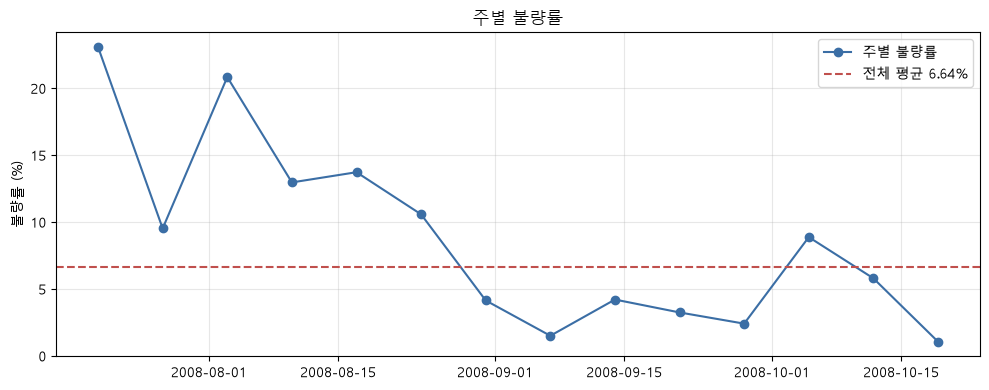

주별 표본 수 / 불량률
            fail_rate    n
timestamp                 
2008-07-20      23.08   13
2008-07-27       9.52   21
2008-08-03      20.83   48
2008-08-10      12.96  108
2008-08-17      13.73   51
2008-08-24      10.58  208
2008-08-31       4.14  169
2008-09-07       1.50  133
2008-09-14       4.21   95
2008-09-21       3.25  154
2008-09-28       2.41  166
2008-10-05       8.88  169
2008-10-12       5.80  138
2008-10-19       1.06   94

분할 시점: 2008-10-02 20:54:00
앞 80%: n=1253, 불량 87개, 불량률 6.94%
뒤 20%: n=314, 불량 17개, 불량률 5.41%
Fisher exact p = 0.376
[셀 끝] 16:20:50 (소요 0.2s)


In [8]:
import time; _t0 = time.time(); print(f"[셀 시작] {time.strftime('%H:%M:%S')}")

from scipy.stats import fisher_exact

plt.rcParams["font.family"] = "Malgun Gothic"   # 한글 폰트 (Windows)
plt.rcParams["axes.unicode_minus"] = False

ts = pd.DataFrame({"timestamp": y["timestamp"], "fail": yb})
weekly = ts.set_index("timestamp")["fail"].resample("W").agg(["mean", "count"])
weekly.columns = ["fail_rate", "n"]
overall = yb.mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(weekly.index, weekly["fail_rate"] * 100, marker="o", color="#3B6EA5", label="주별 불량률")
ax.axhline(overall * 100, color="#C0504D", ls="--", label=f"전체 평균 {overall*100:.2f}%")
ax.set_ylabel("불량률 (%)")
ax.set_title("주별 불량률")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("주별 표본 수 / 불량률")
print(weekly.assign(fail_rate=(weekly["fail_rate"] * 100).round(2)).to_string())

# 시간순 앞 80% / 뒤 20% (이후 셀에서 재사용)
order = np.argsort(y["timestamp"].to_numpy(), kind="stable")
n_tr = int(len(order) * 0.8)
idx_tr, idx_te = order[:n_tr], order[n_tr:]
cut = y["timestamp"].iloc[idx_te[0]]

f_tr, f_te = yb.iloc[idx_tr], yb.iloc[idx_te]
print(f"\n분할 시점: {cut}")
print(f"앞 80%: n={len(f_tr)}, 불량 {f_tr.sum()}개, 불량률 {f_tr.mean()*100:.2f}%")
print(f"뒤 20%: n={len(f_te)}, 불량 {f_te.sum()}개, 불량률 {f_te.mean()*100:.2f}%")
_, p = fisher_exact([[f_tr.sum(), len(f_tr) - f_tr.sum()], [f_te.sum(), len(f_te) - f_te.sum()]])
print(f"Fisher exact p = {p:.3f}")

print(f"[셀 끝] {time.strftime('%H:%M:%S')} (소요 {time.time() - _t0:.1f}s)")

## 3. 공통 평가 함수
모든 모델을 같은 outer CV(`DEV=True`: 10-fold × 1, `False`: 10-fold × 5, `random_state=42`)와 같은 시간순 80/20 분할로 평가하는 `evaluate()`를 정의한다. 전처리는 전부 모델(Pipeline) 안에 있으므로 fold/학습 구간에서만 fit된다.

결측 플래그용 커스텀 transformer `MissingFlagger`도 여기서 정의한다. 학습 데이터에서 결측 비율이 50%를 넘는 컬럼에만 `원래컬럼_na`(0/1) 플래그를 붙이고, 결측 패턴이 완전히 같은 플래그는 첫 번째 하나만 남긴다. 라벨을 쓰지 않는 규칙이라 fold 안에서 fit해도 누수가 없다. 셀 5와 7은 `impute_steps()`(플래그 → 중앙값 대체)를 공통 전처리로 쓴다.

`evaluate(..., tune_threshold=True)`로 부르면 모델을 `TunedThresholdClassifierCV`(balanced accuracy 기준, 내부 StratifiedKFold(5))로 감싼다. 임계값은 각 outer 학습 fold, 그리고 시간순 학습 구간 **안에서만** 정해지므로 누수가 없다. 고른 임계값은 fold별로 출력한다.

In [9]:
import time; _t0 = time.time(); print(f"[셀 시작] {time.strftime('%H:%M:%S')}")

from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV, TunedThresholdClassifierCV
from sklearn.metrics import balanced_accuracy_score, recall_score, average_precision_score, f1_score

DEV = False   # True: 빠른 확인용 (10-fold × 1), False: 최종 (10-fold × 5)

cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=1 if DEV else 5, random_state=42)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # 하이퍼파라미터 튜닝용 (outer 학습 fold 내부)

# 시간순 분할 (셀 2의 idx_tr / idx_te)
X_tr_t, X_te_t = X2.iloc[idx_tr], X2.iloc[idx_te]
y_tr_t, y_te_t = yb.iloc[idx_tr], yb.iloc[idx_te]

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer


class MissingFlagger(BaseEstimator, TransformerMixin):
    """학습 데이터에서 결측 비율 > threshold인 컬럼에만 결측 플래그(원래컬럼_na, 0/1)를 붙인다.
    플래그끼리 완전히 같은 열은 (학습 데이터 기준) 첫 번째 컬럼 것만 남긴다. 원래 컬럼은 그대로 통과 (NaN 유지)."""

    def __init__(self, threshold=0.5):
        self.threshold = threshold

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.feature_names_in_ = np.asarray(X.columns.astype(str), dtype=object)
        self.n_features_in_ = X.shape[1]
        rate = X.isna().mean()
        flags = X.loc[:, rate > self.threshold].isna()
        self.flag_cols_ = list(flags.T.drop_duplicates().index)   # 같은 패턴은 첫 번째만
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        X.columns = self.feature_names_in_
        flags = X[self.flag_cols_].isna().astype(float)
        flags.columns = [f"{c}_na" for c in self.flag_cols_]
        return pd.concat([X, flags], axis=1)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(list(self.feature_names_in_) + [f"{c}_na" for c in self.flag_cols_], dtype=object)


def impute_steps():
    """공통 전처리: 결측 플래그(50% 초과 컬럼) → 중앙값 대체"""
    return [("flag", MissingFlagger(threshold=0.5)),
            ("impute", SimpleImputer(strategy="median"))]


METRICS = ["BER", "recall", "PR_AUC", "F1"]
results = []


def score(model, Xt, yt):
    """BER, 불량 recall, PR-AUC, F1 (불량 = 1 기준)"""
    pred = model.predict(Xt)
    prob = model.predict_proba(Xt)[:, 1]
    return {
        "BER": 1 - balanced_accuracy_score(yt, pred),
        "recall": recall_score(yt, pred, zero_division=0),
        "PR_AUC": average_precision_score(yt, prob),
        "F1": f1_score(yt, pred, zero_division=0),
    }


def _unwrap(m):
    """TunedThresholdClassifierCV → estimator_, GridSearchCV → best_estimator_ 순으로 벗겨서 실제 모델 반환"""
    if hasattr(m, "best_threshold_"):
        m = m.estimator_
    if hasattr(m, "best_estimator_"):
        m = m.best_estimator_
    return m


def count_used(m):
    """모델이 실제로 쓰는 변수 수"""
    m = _unwrap(m)
    if hasattr(m, "named_steps") and "select" in m.named_steps:
        return int(m.named_steps["select"].get_support().sum())
    est = m[-1] if hasattr(m, "steps") else m
    if hasattr(est, "coef_"):                      # 로지스틱: 0이 아닌 계수
        return int(np.count_nonzero(est.coef_))
    if hasattr(est, "booster_"):                   # LightGBM: split에 한 번이라도 쓰인 변수
        return int((est.booster_.feature_importance("split") > 0).sum())
    return int(est.n_features_in_)                 # 그 외: 입력 차원 (결측 플래그 포함)


def evaluate(model, name, tune_threshold=False):
    """(a) outer CV  (b) 시간순 80/20  (c) results에 한 행 추가. 반환: (fold별 학습 모델 리스트, 시간순 학습 모델)
    tune_threshold=True: TunedThresholdClassifierCV로 감싸 학습 데이터 내부 5-fold에서 BER 최소 임계값 선택"""
    if tune_threshold:
        model = TunedThresholdClassifierCV(
            model, scoring="balanced_accuracy",
            cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0))
    fold_scores, fold_models = [], []
    for tr, te in cv.split(X2, yb):
        m = clone(model).fit(X2.iloc[tr], yb.iloc[tr])
        s = score(m, X2.iloc[te], yb.iloc[te])
        s["n_feat"] = count_used(m)
        fold_scores.append(s)
        fold_models.append(m)
    fs = pd.DataFrame(fold_scores)

    m_time = clone(model).fit(X_tr_t, y_tr_t)       # 전처리 포함 학습 구간에서만 fit
    st = score(m_time, X_te_t, y_te_t)

    row = {"model": name}
    for k in METRICS:
        row[f"{k}_mean"] = fs[k].mean()
        row[f"{k}_std"] = fs[k].std()
    for k in METRICS:
        row[f"{k}_time"] = st[k]
    row["n_feat"] = fs["n_feat"].mean()
    row["n_folds"] = len(fs)
    if tune_threshold:
        thr = [m.best_threshold_ for m in fold_models]
        row["thr_mean"], row["thr_std"], row["thr_time"] = np.mean(thr), np.std(thr), m_time.best_threshold_

    results[:] = [r for r in results if r["model"] != name] + [row]   # 재실행 시 같은 이름 행 교체

    print(f"[{name}]  ({len(fs)} folds)")
    print("  CV    : " + " | ".join(
        f"{k} {row[k+'_mean']*100:.1f}±{row[k+'_std']*100:.1f}" if k != "PR_AUC"
        else f"{k} {row[k+'_mean']:.3f}±{row[k+'_std']:.3f}" for k in METRICS))
    print("  시간순: " + " | ".join(
        f"{k} {st[k]*100:.1f}" if k != "PR_AUC" else f"{k} {st[k]:.3f}" for k in METRICS))
    print(f"  사용 변수 수(fold 평균): {row['n_feat']:.1f}")
    if tune_threshold:
        print(f"  임계값 fold별: {np.round(thr, 3).tolist()}")
        print(f"  임계값 평균 {row['thr_mean']:.3f}±{row['thr_std']:.3f} | 시간순 {row['thr_time']:.3f}")
    return fold_models, m_time


print(f"DEV={DEV}, outer folds = {cv.get_n_splits()}")
_mf = MissingFlagger().fit(X_tr_t)   # 참고 출력용: 시간순 학습 구간 기준 (전체 데이터 fit 아님)
print(f"결측 플래그 (시간순 학습 구간 기준): {len(_mf.flag_cols_)}개 → 입력 {X2.shape[1]} + {len(_mf.flag_cols_)} = {X2.shape[1] + len(_mf.flag_cols_)}")
print("  플래그 대상:", _mf.flag_cols_)
print(f"시간순: 학습 {len(y_tr_t)} (불량 {y_tr_t.sum()}) / 테스트 {len(y_te_t)} (불량 {y_te_t.sum()})")

print(f"[셀 끝] {time.strftime('%H:%M:%S')} (소요 {time.time() - _t0:.1f}s)")

[셀 시작] 16:20:51
DEV=False, outer folds = 50
결측 플래그 (시간순 학습 구간 기준): 2개 → 입력 282 + 2 = 284
  플래그 대상: ['f109', 'f157']
시간순: 학습 1253 (불량 87) / 테스트 314 (불량 17)
[셀 끝] 16:20:51 (소요 0.1s)


## 4. 기준선: F-test 40 + 로지스틱
README 10번 파이프라인(중앙값 대체 → 상수 제거 → 표준화 → F-test 상위 40 → balanced 로지스틱)을 공통 평가 함수로 평가한다. 결측 플래그는 넣지 않는다.

In [10]:
import time; _t0 = time.time(); print(f"[셀 시작] {time.strftime('%H:%M:%S')}")

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

base_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("const", VarianceThreshold(0.0)),
    ("scale", StandardScaler()),
    ("select", SelectKBest(f_classif, k=40)),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000)),
])
base_folds, base_time = evaluate(base_pipe, "F-test 40 + 로지스틱")

print(f"[셀 끝] {time.strftime('%H:%M:%S')} (소요 {time.time() - _t0:.1f}s)")

[셀 시작] 16:20:51
[F-test 40 + 로지스틱]  (50 folds)
  CV    : BER 34.4±7.6 | recall 56.0±15.6 | PR_AUC 0.190±0.072 | F1 22.1±5.7
  시간순: BER 36.4 | recall 47.1 | PR_AUC 0.244 | F1 19.0
  사용 변수 수(fold 평균): 40.0
[셀 끝] 16:20:57 (소요 6.6s)


## 5. Ridge / Lasso / Elastic Net 로지스틱 (nested CV)
결측 플래그(`MissingFlagger`, 결측 50% 초과 컬럼만) → 중앙값 대체 → 표준화 → 로지스틱(Ridge: lbfgs, Lasso: liblinear, EN: saga, `tol=1e-3`). C(와 EN의 `l1_ratio`)는 outer 학습 fold 안의 inner 5-fold GridSearchCV로 고른다. `DEV=True`면 grid를 줄인다(C 5개, EN l1_ratio [0.5]). Lasso/EN은 fold마다 0이 아닌 계수를 기록해 **선택 빈도**를 구한다. 비교용으로 EN에 임계값 튜닝(`tune_threshold=True`)을 적용한 버전도 평가한다. 이 버전은 GridSearchCV를 내부 5-fold마다 다시 돌리므로 EN보다 약 6배 오래 걸린다.

> scikit-learn 1.8부터 `penalty=` 인자가 deprecated(1.10 제거)라 `l1_ratio`만 지정한다. `l1_ratio=0` = Ridge(L2), `1` = Lasso(L1), 사이 = Elastic Net이고, `penalty="l2"/"l1"/"elasticnet"`과 같은 동작이다.
> 이전에는 `SimpleImputer(add_indicator=True)`가 결측이 하나라도 있는 컬럼마다 플래그를 만들어 입력이 282 → 533개로 늘었다. 결측 1~2개짜리 플래그와 같은 패턴의 중복 플래그는 노이즈이고 Lasso 수렴을 크게 늦춰서 교체했다.
> ConvergenceWarning은 숨기고, 대신 미수렴 fit 개수를 모델별로 한 번 출력한다 (inner CV fit은 scorer로 `n_iter_ >= max_iter` 여부를 기록해 셈).

In [11]:
import time; _t0 = time.time(); print(f"[셀 시작] {time.strftime('%H:%M:%S')}")

import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)   # 반복 경고 숨김 → 아래에서 개수로 한 번만 표시

MAX_ITER = 5000
C_GRID = np.logspace(-3, 1, 5) if DEV else np.logspace(-3, 1, 9)
EN_L1 = [0.5] if DEV else [0.2, 0.5, 0.8]


def _not_converged(est, X, y):
    """inner CV scorer: 이 fit이 max_iter에 도달했으면 1"""
    clf = est[-1]
    return float(np.max(clf.n_iter_) >= clf.max_iter)


def make_logit(solver, l1_ratios):
    pipe = Pipeline([
        *impute_steps(),
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(solver=solver, class_weight="balanced", tol=1e-3, max_iter=MAX_ITER)),
    ])
    grid = {"clf__C": C_GRID, "clf__l1_ratio": l1_ratios}
    return GridSearchCV(pipe, grid, scoring={"bacc": "balanced_accuracy", "nc": _not_converged},
                        refit="bacc", cv=inner_cv, n_jobs=-1)


def report_convergence(name, folds, m_time):
    """inner CV fit + outer/시간순 refit 중 미수렴 개수"""
    gs = folds + [m_time]
    inner = sum(g.cv_results_[f"split{i}_test_nc"].sum() for g in gs for i in range(g.n_splits_))
    n_inner = sum(len(g.cv_results_["params"]) * g.n_splits_ for g in gs)
    refit = sum(np.max(g.best_estimator_[-1].n_iter_) >= MAX_ITER for g in gs)
    total = int(inner + refit)
    msg = f"  ConvergenceWarning: 미수렴 {total} / {n_inner + len(gs)} fits (inner {int(inner)}, refit {int(refit)})"
    print(msg if total else f"  수렴 OK: {n_inner + len(gs)} fits 모두 수렴")


print(f"DEV={DEV}: C {len(C_GRID)}개, EN l1_ratio {EN_L1}")

ridge_folds, ridge_time = evaluate(make_logit("lbfgs", [0.0]), "Ridge 로지스틱")
report_convergence("Ridge", ridge_folds, ridge_time)
lasso_folds, lasso_time = evaluate(make_logit("liblinear", [1.0]), "Lasso 로지스틱")
report_convergence("Lasso", lasso_folds, lasso_time)
enet_folds, enet_time = evaluate(make_logit("saga", EN_L1), "ElasticNet 로지스틱")
report_convergence("ElasticNet", enet_folds, enet_time)
enet_thr_folds, enet_thr_time = evaluate(make_logit("saga", EN_L1), "ElasticNet 로지스틱 (임계값 튜닝)", tune_threshold=True)


def selection_freq(folds):
    """fold별 0이 아닌 계수 선택 빈도 + 평균 계수 (특징 이름은 get_feature_names_out)"""
    coefs = []
    for m in folds:
        best = m.best_estimator_
        names = best[:-1].get_feature_names_out()
        coefs.append(pd.Series(best[-1].coef_.ravel(), index=names))
    C = pd.concat(coefs, axis=1).fillna(0.0)
    out = pd.DataFrame({"freq": (C != 0).mean(axis=1), "mean_coef": C.mean(axis=1)})
    return out.sort_values(["freq", "mean_coef"], ascending=[False, False], key=lambda s: s.abs() if s.name == "mean_coef" else s)


lasso_sel = selection_freq(lasso_folds)
enet_sel = selection_freq(enet_folds)

for name, folds, sel in [("Lasso", lasso_folds, lasso_sel), ("ElasticNet", enet_folds, enet_sel)]:
    n_used = [int(np.count_nonzero(m.best_estimator_[-1].coef_)) for m in folds]
    params = pd.Series([f"C={m.best_params_['clf__C']:.3g}, l1={m.best_params_['clf__l1_ratio']}" for m in folds]).value_counts()
    print(f"\n=== {name} ===")
    print(f"평균 사용 변수 수: {np.mean(n_used):.1f} (fold별 {n_used})")
    print(f"선택 빈도 80% 이상: {(sel['freq'] >= 0.8).sum()}개")
    print("fold별 best params:", dict(params))
    display(sel.head(30).style.format({"freq": "{:.0%}", "mean_coef": "{:+.3f}"}).set_caption(f"{name} 선택 빈도 상위 30"))

print(f"[셀 끝] {time.strftime('%H:%M:%S')} (소요 {time.time() - _t0:.1f}s)")

[셀 시작] 16:20:57
DEV=False: C 9개, EN l1_ratio [0.2, 0.5, 0.8]
[Ridge 로지스틱]  (50 folds)
  CV    : BER 37.3±7.1 | recall 45.7±13.7 | PR_AUC 0.193±0.067 | F1 21.3±6.2
  시간순: BER 45.8 | recall 11.8 | PR_AUC 0.205 | F1 13.8
  사용 변수 수(fold 평균): 284.8
  수렴 OK: 2346 fits 모두 수렴
[Lasso 로지스틱]  (50 folds)
  CV    : BER 31.7±6.9 | recall 66.3±14.8 | PR_AUC 0.198±0.073 | F1 22.8±4.7
  시간순: BER 45.5 | recall 11.8 | PR_AUC 0.098 | F1 14.8
  사용 변수 수(fold 평균): 28.4
  수렴 OK: 2346 fits 모두 수렴


KeyboardInterrupt: 

In [12]:
enet_folds, enet_time = evaluate(make_logit("saga", [0.5]), "ElasticNet 로지스틱")
report_convergence("ElasticNet", enet_folds, enet_time)


def selection_freq(folds):
    """fold별 0이 아닌 계수 선택 빈도 + 평균 계수 (특징 이름은 get_feature_names_out)"""
    coefs = []
    for m in folds:
        best = m.best_estimator_
        names = best[:-1].get_feature_names_out()
        coefs.append(pd.Series(best[-1].coef_.ravel(), index=names))
    C = pd.concat(coefs, axis=1).fillna(0.0)
    out = pd.DataFrame({"freq": (C != 0).mean(axis=1), "mean_coef": C.mean(axis=1)})
    return out.sort_values(["freq", "mean_coef"], ascending=[False, False], key=lambda s: s.abs() if s.name == "mean_coef" else s)


lasso_sel = selection_freq(lasso_folds)
enet_sel = selection_freq(enet_folds)

for name, folds, sel in [("Lasso", lasso_folds, lasso_sel), ("ElasticNet", enet_folds, enet_sel)]:
    n_used = [int(np.count_nonzero(m.best_estimator_[-1].coef_)) for m in folds]
    params = pd.Series([f"C={m.best_params_['clf__C']:.3g}, l1={m.best_params_['clf__l1_ratio']}" for m in folds]).value_counts()
    print(f"\n=== {name} ===")
    print(f"평균 사용 변수 수: {np.mean(n_used):.1f} (fold별 {n_used})")
    print(f"선택 빈도 80% 이상: {(sel['freq'] >= 0.8).sum()}개")
    print("fold별 best params:", dict(params))
    display(sel.head(30).style.format({"freq": "{:.0%}", "mean_coef": "{:+.3f}"}).set_caption(f"{name} 선택 빈도 상위 30"))

print(f"[셀 끝] {time.strftime('%H:%M:%S')} (소요 {time.time() - _t0:.1f}s)")


en_thr = TunedThresholdClassifierCV(
    make_logit("saga", [0.5]), scoring="balanced_accuracy",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
).fit(X_tr_t, y_tr_t)
s = score(en_thr, X_te_t, y_te_t)
print("EN 임계값 튜닝 (시간순):", {k: round(v, 3) for k, v in s.items()},
      "| 임계값", round(en_thr.best_threshold_, 3))

[ElasticNet 로지스틱]  (50 folds)
  CV    : BER 32.7±6.7 | recall 56.5±13.1 | PR_AUC 0.204±0.077 | F1 24.5±6.2
  시간순: BER 39.9 | recall 23.5 | PR_AUC 0.224 | F1 25.8
  사용 변수 수(fold 평균): 38.8
  수렴 OK: 2346 fits 모두 수렴

=== Lasso ===
평균 사용 변수 수: 28.4 (fold별 [6, 60, 55, 6, 7, 9, 8, 59, 8, 7, 59, 52, 10, 61, 6, 8, 8, 5, 56, 58, 61, 61, 60, 6, 7, 57, 8, 54, 7, 8, 62, 7, 6, 9, 57, 59, 53, 7, 8, 5, 56, 6, 7, 54, 8, 65, 54, 6, 8, 7])
선택 빈도 80% 이상: 5개
fold별 best params: {'C=0.01, l1=1.0': np.int64(29), 'C=0.0316, l1=1.0': np.int64(21)}


,freq,mean_coef
f59,100%,+0.358
f103,96%,+0.103
f21,96%,+0.089
f348,96%,+0.071
f129,92%,+0.144
f64,74%,+0.112
f510,70%,+0.037
f121,62%,+0.081
f130,44%,+0.050
f14,44%,-0.038



=== ElasticNet ===
평균 사용 변수 수: 38.8 (fold별 [37, 40, 38, 3, 44, 36, 40, 40, 34, 42, 36, 113, 33, 39, 4, 40, 46, 41, 43, 38, 37, 39, 41, 3, 39, 36, 36, 36, 39, 36, 116, 42, 36, 41, 35, 40, 36, 32, 38, 39, 38, 40, 41, 33, 4, 43, 36, 42, 40, 37])
선택 빈도 80% 이상: 20개
fold별 best params: {'C=0.01, l1=0.5': np.int64(44), 'C=0.00316, l1=0.5': np.int64(4), 'C=0.0316, l1=0.5': np.int64(2)}


,freq,mean_coef
f59,100%,+0.319
f103,100%,+0.112
f348,96%,+0.091
f129,92%,+0.174
f64,92%,+0.108
f21,92%,+0.102
f121,92%,+0.102
f31,92%,-0.084
f130,92%,+0.070
f146,90%,-0.052


[셀 끝] 17:35:16 (소요 4458.8s)
EN 임계값 튜닝 (시간순): {'BER': 0.416, 'recall': 0.235, 'PR_AUC': 0.224, 'F1': 0.195} | 임계값 0.469


## 6. LightGBM + SHAP
NaN을 그대로 넣는 LightGBM(`class_weight="balanced"`)을 평가한다.
- 기본 파라미터에서는 CV와 시간순 모두 recall 0(BER 50)이었다. 그런데 PR-AUC는 0.214로, 구별력은 있지만 확률이 임계값 0.5를 넘지 못했다.
- 그래서 과적합을 줄이는 파라미터(트리 300개, lr 0.03, 잎 15개, 행/열 서브샘플링, L2 규제)를 쓰고 `tune_threshold=True`로 평가한다.
- `get_params()`로 `class_weight`가 실제로 들어갔는지 확인한다. 이어서 시간순 학습 구간으로 학습한 모델에 SHAP TreeExplainer를 적용해 (학습 구간 기준) 평균 |SHAP| 상위 20개 표와 summary plot을 그린다.

[셀 시작] 17:37:08
get_params(): {'boosting_type': 'gbdt', 'class_weight': 'balanced', 'colsample_bytree': 0.5, 'importance_type': 'split', 'learning_rate': 0.03, 'max_depth': -1, 'min_child_samples': 20, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 300, 'n_jobs': None, 'num_leaves': 15, 'objective': None, 'random_state': 42, 'reg_alpha': 0.0, 'reg_lambda': 1.0, 'subsample': 0.8, 'subsample_for_bin': 200000, 'subsample_freq': 1, 'verbose': -1}
class_weight = balanced
[LightGBM (임계값 튜닝)]  (50 folds)
  CV    : BER 31.8±6.1 | recall 72.5±13.4 | PR_AUC 0.240±0.087 | F1 21.5±3.9
  시간순: BER 43.0 | recall 35.3 | PR_AUC 0.107 | F1 14.0
  사용 변수 수(fold 평균): 277.2
  임계값 fold별: [0.028, 0.036, 0.026, 0.024, 0.043, 0.032, 0.056, 0.033, 0.024, 0.03, 0.038, 0.025, 0.039, 0.018, 0.018, 0.025, 0.022, 0.023, 0.022, 0.026, 0.033, 0.024, 0.024, 0.026, 0.031, 0.045, 0.032, 0.025, 0.019, 0.02, 0.029, 0.037, 0.022, 0.033, 0.035, 0.027, 0.021, 0.038, 0.046, 0.027, 0.026, 0.022, 0.025, 0.026, 

c:\Users\Thinkpad\anaconda3\envs\work\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


,mean|SHAP|
f59,0.4166
f460,0.2462
f247,0.1555
f33,0.1503
f21,0.1430
f10,0.1160
f19,0.1152
f172,0.1126
f0,0.1032
f488,0.0974


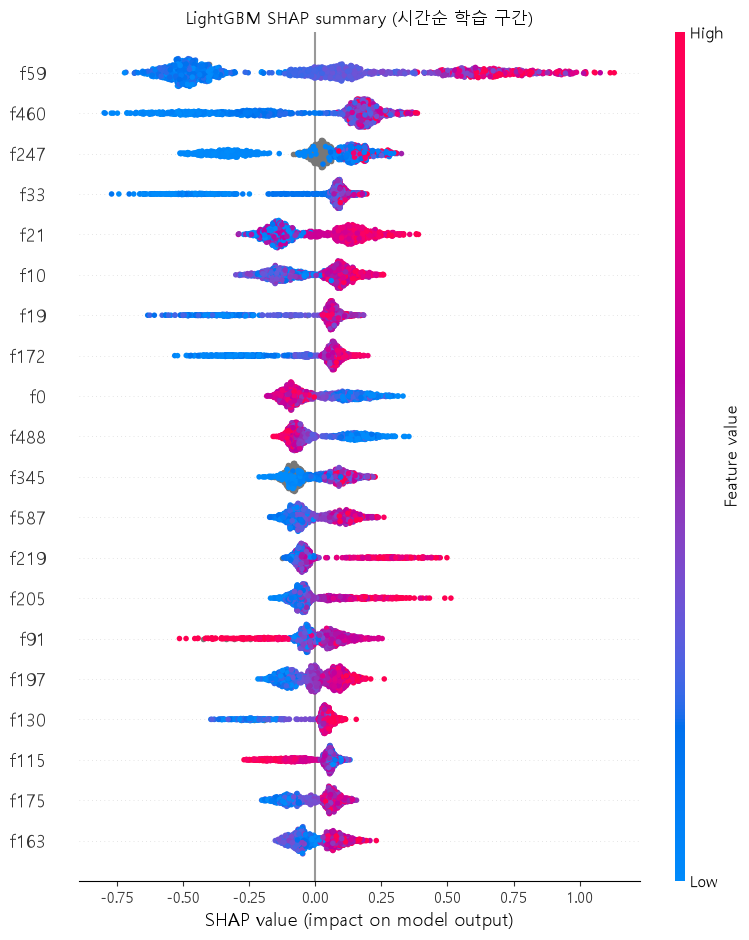

[셀 끝] 17:44:47 (소요 459.0s)


In [13]:
import time; _t0 = time.time(); print(f"[셀 시작] {time.strftime('%H:%M:%S')}")

from lightgbm import LGBMClassifier
import shap

lgbm = LGBMClassifier(
    class_weight="balanced", random_state=42, verbose=-1,
    n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=20,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1.0,
)
print("get_params():", lgbm.get_params())
print("class_weight =", lgbm.get_params()["class_weight"])

lgbm_folds, lgbm_time = evaluate(lgbm, "LightGBM (임계값 튜닝)", tune_threshold=True)
print("학습된 모델의 class_weight =", lgbm_time.estimator_.get_params()["class_weight"])   # clone 후에도 유지되는지

explainer = shap.TreeExplainer(lgbm_time.estimator_)   # 임계값 래퍼 안의 실제 LightGBM
sv = explainer.shap_values(X_tr_t)
if isinstance(sv, list):        # 버전에 따라 클래스별 리스트로 반환
    sv = sv[1]
elif sv.ndim == 3:
    sv = sv[:, :, 1]

shap_imp = pd.Series(np.abs(sv).mean(axis=0), index=X2.columns, name="mean|SHAP|").sort_values(ascending=False)
display(shap_imp.head(20).to_frame().style.format("{:.4f}").set_caption("평균 |SHAP| 상위 20 (시간순 학습 구간)"))

shap.summary_plot(sv, X_tr_t, max_display=20, show=False)
plt.title("LightGBM SHAP summary (시간순 학습 구간)")
plt.tight_layout()
plt.show()

print(f"[셀 끝] {time.strftime('%H:%M:%S')} (소요 {time.time() - _t0:.1f}s)")

## 7. (선택) 비교: 불균형 처리 방식(SMOTE) + DL(MLP)
다른 셀과 같은 `evaluate()`와 같은 fold로 두 모델을 평가하고, 마지막에 지금까지의 results를 짧은 비교표로 출력한다.
- **7-1. SMOTE + ElasticNet**
  - imblearn Pipeline: `impute_steps()` → 표준화 → SMOTE → saga 로지스틱(`l1_ratio=0.5`). sklearn Pipeline에는 SMOTE를 넣을 수 없다.
  - SMOTE와 `class_weight`를 같이 쓰면 불균형을 두 번 보정하게 되므로 `class_weight=None`으로 둔다.
  - C는 셀 5와 같은 grid(`C_GRID`)에서 inner CV로 고른다.
  - SMOTE는 파이프라인 안에 있어서 학습 fold에서만 합성 표본을 만들고, 테스트 fold에는 적용되지 않는다.
  - 셀 5의 "ElasticNet 로지스틱"(class_weight 방식, 임계값 튜닝 없음)과 직접 비교하기 위한 모델이다.
- **7-2. MLP (sklearn)**
  - `impute_steps()` → 표준화 → MLPClassifier(64, `alpha=1e-3`, early stopping)
  - MLPClassifier에는 class_weight 옵션이 없어서 `tune_threshold=True`(학습 fold 내부에서 임계값 결정)로 불균형을 보정한다.

In [14]:
import time; _t0 = time.time(); print(f"[셀 시작] {time.strftime('%H:%M:%S')}")

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.neural_network import MLPClassifier

# ----- 7-1. SMOTE + ElasticNet (class_weight=None: SMOTE로만 불균형 보정) -----
smote_pipe = ImbPipeline([
    *impute_steps(),
    ("scale", StandardScaler()),
    ("smote", SMOTE(random_state=42)),          # 학습 fold에서만 합성 표본 생성
    ("clf", LogisticRegression(solver="saga", l1_ratio=0.5, class_weight=None, tol=1e-3, max_iter=5000)),
])
smote_gs = GridSearchCV(smote_pipe, {"clf__C": C_GRID}, scoring="balanced_accuracy", cv=inner_cv, n_jobs=-1)
smote_folds, smote_time = evaluate(smote_gs, "SMOTE + ElasticNet", tune_threshold=False)
print("  fold별 best C:", dict(pd.Series([f"{m.best_params_['clf__C']:.3g}" for m in smote_folds]).value_counts()))

# ----- 7-2. MLP (class_weight 없음 → 임계값 튜닝으로 보정) -----
mlp_pipe = Pipeline([
    *impute_steps(),
    ("scale", StandardScaler()),
    ("clf", MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, early_stopping=True, max_iter=500, random_state=42)),
])
mlp_folds, mlp_time = evaluate(mlp_pipe, "MLP (임계값 튜닝)", tune_threshold=True)

# ----- 지금까지 결과 비교표 -----
_r = pd.DataFrame(results)
cmp = pd.DataFrame({
    "모델": _r["model"],
    "CV BER (%)": [f"{m*100:.1f} ± {s*100:.1f}" for m, s in zip(_r["BER_mean"], _r["BER_std"])],
    "CV PR-AUC": [f"{m:.3f} ± {s:.3f}" for m, s in zip(_r["PR_AUC_mean"], _r["PR_AUC_std"])],
    "시간순 BER (%)": (_r["BER_time"] * 100).round(1),
    "시간순 PR-AUC": _r["PR_AUC_time"].round(3),
})
display(cmp)

print(f"[셀 끝] {time.strftime('%H:%M:%S')} (소요 {time.time() - _t0:.1f}s)")

[셀 시작] 17:44:47
[SMOTE + ElasticNet]  (50 folds)
  CV    : BER 31.2±6.7 | recall 57.7±14.1 | PR_AUC 0.197±0.061 | F1 26.4±6.4
  시간순: BER 50.5 | recall 0.0 | PR_AUC 0.163 | F1 0.0
  사용 변수 수(fold 평균): 13.6
  fold별 best C: {'0.00316': np.int64(50)}
[MLP (임계값 튜닝)]  (50 folds)
  CV    : BER 38.7±7.0 | recall 66.4±22.8 | PR_AUC 0.191±0.090 | F1 17.6±4.7
  시간순: BER 47.5 | recall 11.8 | PR_AUC 0.142 | F1 10.3
  사용 변수 수(fold 평균): 284.9
  임계값 fold별: [0.12, 0.135, 0.103, 0.162, 0.152, 0.14, 0.124, 0.148, 0.125, 0.101, 0.212, 0.118, 0.143, 0.103, 0.072, 0.189, 0.11, 0.111, 0.197, 0.131, 0.165, 0.123, 0.212, 0.109, 0.131, 0.118, 0.065, 0.212, 0.152, 0.15, 0.12, 0.17, 0.116, 0.071, 0.17, 0.184, 0.118, 0.162, 0.217, 0.136, 0.152, 0.141, 0.14, 0.136, 0.202, 0.212, 0.141, 0.232, 0.131, 0.082]
  임계값 평균 0.143±0.040 | 시간순 0.198


,모델,CV BER (%),CV PR-AUC,시간순 BER (%),시간순 PR-AUC
0,F-test 40 + 로지스틱,34.4 ± 7.6,0.190 ± 0.072,36.4,0.244
1,Ridge 로지스틱,37.3 ± 7.1,0.193 ± 0.067,45.8,0.205
2,Lasso 로지스틱,31.7 ± 6.9,0.198 ± 0.073,45.5,0.098
3,ElasticNet 로지스틱,32.7 ± 6.7,0.204 ± 0.077,39.9,0.224
4,LightGBM (임계값 튜닝),31.8 ± 6.1,0.240 ± 0.087,43.0,0.107
5,SMOTE + ElasticNet,31.2 ± 6.7,0.197 ± 0.061,50.5,0.163
6,MLP (임계값 튜닝),38.7 ± 7.0,0.191 ± 0.090,47.5,0.142


[셀 끝] 18:20:34 (소요 2146.7s)


## 8. 정리
모델별 결과 표를 만들고, 세 방법(L1 선택 빈도 ≥ 80%, SHAP 상위 20, F-test 상위 40)의 변수 목록 교집합과 EDA 후보 13개와의 겹침을 확인한 뒤 `data/processed/model_results.csv`로 저장한다.
- L1 목록은 Lasso 기준 (EN은 참고 출력). 결측 플래그(`fX_na`)는 원 변수 `fX`로 합쳐 비교한다.
- F-test 상위 40은 전체 데이터에 fit하지 않고, 기준선의 fold별 SelectKBest 선택 빈도(동률이면 평균 F 점수) 상위 40으로 정한다.

In [15]:
import time; _t0 = time.time(); print(f"[셀 시작] {time.strftime('%H:%M:%S')}")

res = pd.DataFrame(results)

def pm(r, k, pct=True):
    return f"{r[k+'_mean']*100:.1f} ± {r[k+'_std']*100:.1f}" if pct else f"{r[k+'_mean']:.3f} ± {r[k+'_std']:.3f}"

summary = pd.DataFrame({
    "모델": res["model"],
    "BER CV (%)": res.apply(pm, axis=1, k="BER"),
    "BER 시간순 (%)": (res["BER_time"] * 100).round(1),
    "recall CV (%)": res.apply(pm, axis=1, k="recall"),
    "PR-AUC CV": res.apply(pm, axis=1, k="PR_AUC", pct=False),
    "F1 CV (%)": res.apply(pm, axis=1, k="F1"),
    "사용 변수 수": res["n_feat"].round(1),
})
display(summary)

# ----- 변수 목록 -----
base_name = lambda f: f[:-3] if f.endswith("_na") else f   # fX_na → fX

l1_stable = {base_name(f) for f in lasso_sel.index[lasso_sel["freq"] >= 0.8]}
en_stable = {base_name(f) for f in enet_sel.index[enet_sel["freq"] >= 0.8]}
shap_top20 = set(shap_imp.head(20).index)

ft = []
for m in base_folds:
    sel = m.named_steps["select"]
    names_in = m[:3].get_feature_names_out()          # select 직전 (상수 제거 후) 이름
    ft.append(pd.DataFrame({"feat": names_in, "chosen": sel.get_support(), "F": sel.scores_}))
ft = pd.concat(ft).groupby("feat").agg(freq=("chosen", "mean"), F=("F", "mean"))
ftest_top40 = set(ft.sort_values(["freq", "F"], ascending=False).head(40).index)

EDA = ["f59", "f103", "f247", "f111", "f510", "f205", "f33", "f348", "f28", "f21", "f125", "f129", "f385"]
fsort = lambda s: sorted(s, key=lambda f: int(f[1:]))

lists = {"L1(Lasso) ≥80%": l1_stable, "SHAP 상위 20": shap_top20, "F-test 상위 40": ftest_top40}
print("(참고) ElasticNet ≥80%:", len(en_stable), "개")
for k, s in lists.items():
    print(f"{k:16s}: {len(s):3d}개 | EDA 후보와 겹침 {fsort(s & set(EDA))}")

common = l1_stable & shap_top20 & ftest_top40
print("\n세 목록 교집합:", fsort(common))
print("교집합 ∩ EDA 후보:", fsort(common & set(EDA)))

pair = {
    "L1 ∩ SHAP": l1_stable & shap_top20,
    "L1 ∩ F-test": l1_stable & ftest_top40,
    "SHAP ∩ F-test": shap_top20 & ftest_top40,
}
for k, s in pair.items():
    print(f"{k:14s}: {fsort(s)}")

# EDA 후보별 어느 목록에 들어갔는지
display(pd.DataFrame({k: [f in s for f in EDA] for k, s in lists.items()}, index=EDA).replace({True: "O", False: ""}))

out = here("data/processed/model_results.csv")
res.to_csv(out, index=False, encoding="utf-8-sig")
print("저장:", out)

print(f"[셀 끝] {time.strftime('%H:%M:%S')} (소요 {time.time() - _t0:.1f}s)")

[셀 시작] 18:20:34


,모델,BER CV (%),BER 시간순 (%),recall CV (%),PR-AUC CV,F1 CV (%),사용 변수 수
0,F-test 40 + 로지스틱,34.4 ± 7.6,36.4,56.0 ± 15.6,0.190 ± 0.072,22.1 ± 5.7,40.0
1,Ridge 로지스틱,37.3 ± 7.1,45.8,45.7 ± 13.7,0.193 ± 0.067,21.3 ± 6.2,284.8
2,Lasso 로지스틱,31.7 ± 6.9,45.5,66.3 ± 14.8,0.198 ± 0.073,22.8 ± 4.7,28.4
3,ElasticNet 로지스틱,32.7 ± 6.7,39.9,56.5 ± 13.1,0.204 ± 0.077,24.5 ± 6.2,38.8
4,LightGBM (임계값 튜닝),31.8 ± 6.1,43.0,72.5 ± 13.4,0.240 ± 0.087,21.5 ± 3.9,277.2
5,SMOTE + ElasticNet,31.2 ± 6.7,50.5,57.7 ± 14.1,0.197 ± 0.061,26.4 ± 6.4,13.6
6,MLP (임계값 튜닝),38.7 ± 7.0,47.5,66.4 ± 22.8,0.191 ± 0.090,17.6 ± 4.7,284.9


(참고) ElasticNet ≥80%: 20 개
L1(Lasso) ≥80%  :   5개 | EDA 후보와 겹침 ['f21', 'f59', 'f103', 'f129', 'f348']
SHAP 상위 20      :  20개 | EDA 후보와 겹침 ['f21', 'f33', 'f59', 'f205', 'f247']
F-test 상위 40    :  40개 | EDA 후보와 겹침 ['f21', 'f28', 'f33', 'f59', 'f103', 'f111', 'f125', 'f129', 'f247', 'f348', 'f510']

세 목록 교집합: ['f21', 'f59']
교집합 ∩ EDA 후보: ['f21', 'f59']
L1 ∩ SHAP     : ['f21', 'f59']
L1 ∩ F-test   : ['f21', 'f59', 'f103', 'f129', 'f348']
SHAP ∩ F-test : ['f21', 'f33', 'f59', 'f130', 'f163', 'f247', 'f460']


,L1(Lasso) ≥80%,SHAP 상위 20,F-test 상위 40
f59,O,O,O
f103,O,,O
f247,,O,O
f111,,,O
f510,,,O
f205,,O,
f33,,O,O
f348,O,,O
f28,,,O
f21,O,O,O


저장: c:\Users\Thinkpad\Desktop\python\SECOM\data\processed\model_results.csv
[셀 끝] 18:20:34 (소요 0.2s)
